# Chapter 5: Decision Trees

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

In [2]:
import warnings
warnings.filterwarnings("ignore")

## 5.1 Introduction & Motivation

We have already seen a first classification model. However, There are plenty more models we can work with. One of these is Decision Trees. In decision trees we starting at the root and create leaves or $nodes$ by asking questions. For example when predicting an animal type this could be 'Does the animal have a tail?'. For each node we ask aditional questions.

## 5.2 Problem Setting

When it comes to wine, there are various degrees of quality. Some people are experts in this field, others pretend to be. Today we are going to try and beat the experts by predicting the exact quality of wine based on its features. This quality can range from 0 up to 10 where 0 is the lowest quality and 10 is the highest quality.

## 5.3 Model

First, let's have a look at the data.

In [2]:
df = pd.read_csv("Wine.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000,1142.000000
mean,8.313222,0.531239,0.268494,2.532618,0.086943,15.601138,45.916375,0.996732,3.310788,0.657662,10.442323,5.657618,804.275832
std,1.746902,0.179680,0.196723,1.356420,0.047287,10.243489,32.796444,0.001926,0.156545,0.170466,1.082646,0.805942,463.607311
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.391250,0.090000,1.900000,0.070000,7.000000,21.000000,0.995572,3.202500,0.550000,9.500000,5.000000,410.500000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996690,3.310000,0.620000,10.200000,6.000000,793.500000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997847,3.400000,0.730000,11.100000,6.000000,1208.750000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1595.000000


In [45]:
df["quality"]

0       5
1       5
2       5
3       6
4       5
       ..
1137    6
1138    6
1139    6
1140    5
1141    6
Name: quality, Length: 1142, dtype: int64

##### Question 1: Consider the data above. Are there columns that will not add any value to our model? Elaborate and drop those columns.

<Axes: >

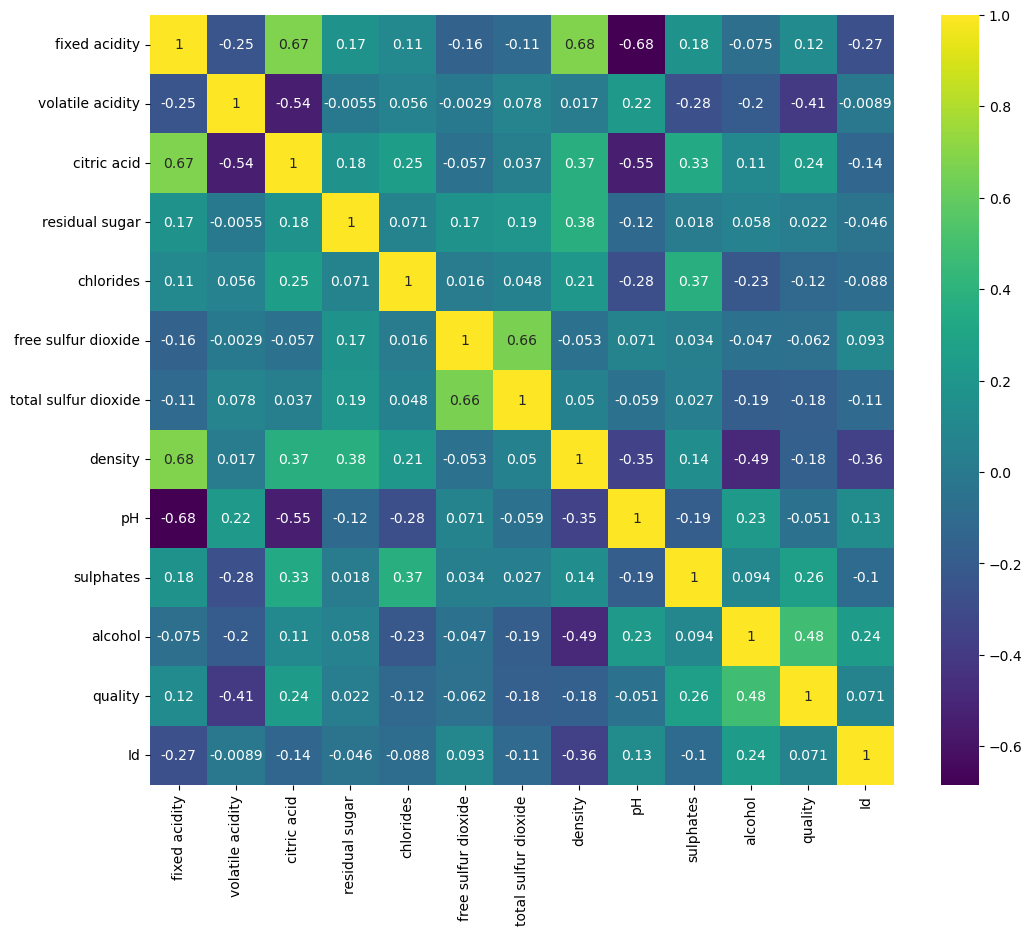

In [9]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), cmap="viridis", annot=True)

##### Question 2: Just as always, explore the data by creating a heatmap. Which variables would you expect to have the highest impact on quality and which ones would you expect to have the lowest impact? Why?

- volatile acidity
- alcohol
- sulphates
- citric acid

##### Question 3: Create a train and test split of the data. Keep 30% of your data as testing data. Build your model using all data except the columns you droped during question 1.

In [95]:
X = df[["volatile acidity", "alcohol", "sulphates", "citric acid", "density"]]
y = df["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [89]:
y.unique()

array([5, 6, 7, 4, 8, 3], dtype=int64)

In [65]:
TreeModel = DecisionTreeClassifier()
TreeModel.fit(X_train, y_train)

accuracy = TreeModel.score(X_test, y_test)
print("Accuracy:",accuracy)

mypred = TreeModel.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print("Precision:",Precision)

SS = specificity_score(y_test, mypred, average="weighted")
print("Specificity score:",SS)

RecallScore = recall_score(y_test, mypred, average="weighted")
print("Recall score:",RecallScore)

F1score = f1_score(y_test, mypred, average="weighted")
print("F1 score:",F1score)

Accuracy: 0.5743440233236151
Precision: 0.5767795720490142
Specificity score: 0.7584703468009547
Recall score: 0.5743440233236151
F1 score: 0.5746689716005402


In [96]:
ClassModel = LogisticRegression(max_iter=10000)
ClassModel.fit(X_train, y_train)

accuracy = ClassModel.score(X_test, y_test)
print("Accuracy:",accuracy)

mypred = ClassModel.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print("Precision:",Precision)

SS = specificity_score(y_test, mypred, average="weighted")
print("Specificity score:",SS)

RecallScore = recall_score(y_test, mypred, average="weighted")
print("Recall score:",RecallScore)

F1score = f1_score(y_test, mypred, average="weighted")
print("F1 score:",F1score)

Accuracy: 0.6443148688046647
Precision: 0.6113538550856334
Specificity score: 0.7649791293028496
Recall score: 0.6443148688046647
F1 score: 0.6227449693084203


##### Question 4: Consider a bottle of wine below. What would be the quality of this wine?

| fixed acidity | volatile acidity | citric acid | residual sugar | chlorides | free sulfur dioxide | total sulfur dioxide | density | pH | sulphates | alcohol | Id |
| --- | --- | --- |--- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5.9 | 0.645 | 0.12 | 2.0 | 0.075 | 32.0 | 44.0 | 0.9954 | 3.57 | 0.71 | 10.2 | 178 |

In [67]:
result = ClassModel.predict([[0.645, 10.2, 0.71, 0.12, 0.9954]])
print(result)

[5]


## 5.4 Model Evaluation

Of course our predictions don't mean anything without knowing how good they are. Let's explore this.

##### Question 5: Calculate accuracy and precision for your model. Are these values any good? Elaborate based on the formulas and meaning of the metrics.

In [68]:
accuracy = ClassModel.score(X_test, y_test)
print("Accuracy:",accuracy)

mypred = ClassModel.predict(X_test)
Precision = precision_score(y_test, mypred, average="weighted")
print("Precision:",Precision)


Accuracy: 0.6443148688046647
Precision: 0.6113538550856334


#### Evaluation

Accuracy of 64%, meaning that around 64% of all predictions are correct.

Precision of 61%, meaning that around 61% of consistent data is predicted correctly.

Whilst these percentages aren't bad, they are not good either. This model would barely be considered 'viable'. There is a lot of room for improvement

##### Question 6: Plot the confuson matrix. How can you visually confirm your previous findings?

Text(0.5, 1.0, 'Accuracy Score: 0.6443148688046647')

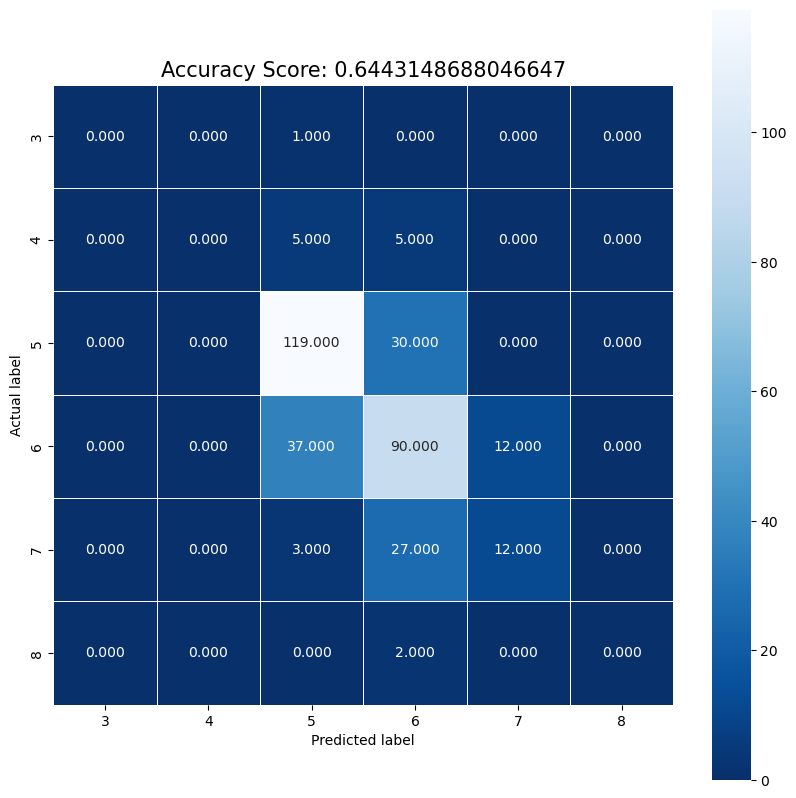

In [97]:
test_pred = ClassModel.predict(X_test)
cm = metrics.confusion_matrix(y_test, test_pred)

labels = [3, 4, 5, 6, 7, 8]

plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r', xticklabels=labels, yticklabels=labels)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
all_sample_title = 'Accuracy Score: {0}'.format(accuracy)
plt.title(all_sample_title, size = 15)

In [98]:
pd.Series(test_pred).value_counts()

5    165
6    154
7     24
Name: count, dtype: int64

The heatmap reveals that most predictions are correct, but a significant portion is still predicted incorrectly. 

This makes sense as our accuracy percentage was around 64%. The majority is predicted correctly, but a rather large chunk of predictions are still incorrect.

##### Question 7: Think back to the introduction of this dataset. Does the confusion matrix make sense? Do the labels actually mean what you assume they mean? Explore the predictions and read the documentation to figure it what is going on and how to properly interpret the confusion matrix.

*Hint: pandas might have some useful methods to analyse a single column*

In [87]:
df["quality"].unique()

array([5, 6, 7, 4, 8, 3], dtype=int64)

## 5.5 Questions

##### Question 1: See section 5.3

##### Question 2: See section 5.3

##### Question 3: See section 5.3

##### Question 4: See section 5.3

##### Question 5: See section 5.4

##### Question 6: See section 5.4

##### Question 7: See section 5.4

##### Question 8: We know our decision tree model works by creating different nodes. Just how many nodes are we creating? Experiment a bit (or google it/ask chatGPT if you are lazy :P) to find this out.

In [101]:
TreeModel.get_depth()

16

In [105]:
from sklearn import tree
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(250, 200))

tree.plot_tree(
    TreeModel
)

fig.savefig("tree.png")

plt.show()

In [110]:
Iarray = []
AccScore = []
AccTrainScore = []

for i in range(1, 100):
    print("MAX DEPTH:", i)
    TreeModel = DecisionTreeClassifier(max_depth=i)
    TreeModel.fit(X_train, y_train)

    accuracy = TreeModel.score(X_test, y_test)
    TRAINacc = TreeModel.score(X_train, y_train)
    print("Accuracy:",accuracy)

    mypred = TreeModel.predict(X_test)
    Precision = precision_score(y_test, mypred, average="weighted")
    print("Precision:",Precision)

    SS = specificity_score(y_test, mypred, average="weighted")
    print("Specificity score:",SS)

    RecallScore = recall_score(y_test, mypred, average="weighted")
    print("Recall score:",RecallScore)

    F1score = f1_score(y_test, mypred, average="weighted")
    print("F1 score:",F1score)

    AccScore.append(accuracy)
    AccTrainScore.append(TRAINacc)
    Iarray.append(i)

    print("__________________")

MAX DEPTH: 1
Accuracy: 0.6180758017492711
Precision: 0.517394434354538
Specificity score: 0.7246066320489905
Recall score: 0.6180758017492711
F1 score: 0.5631276336368222
__________________
MAX DEPTH: 2
Accuracy: 0.6064139941690962
Precision: 0.5703642447276669
Specificity score: 0.7498343311020336
Recall score: 0.6064139941690962
F1 score: 0.5839769999479912
__________________
MAX DEPTH: 3
Accuracy: 0.6239067055393586
Precision: 0.5914041324787902
Specificity score: 0.7576450520613082
Recall score: 0.6239067055393586
F1 score: 0.6044344752396166
__________________
MAX DEPTH: 4
Accuracy: 0.6209912536443148
Precision: 0.597390135438973
Specificity score: 0.7638928865637004
Recall score: 0.6209912536443148
F1 score: 0.6049393895164042
__________________
MAX DEPTH: 5
Accuracy: 0.6034985422740525
Precision: 0.5897069120758537
Specificity score: 0.763113400848604
Recall score: 0.6034985422740525
F1 score: 0.592518706699329
__________________
MAX DEPTH: 6
Accuracy: 0.5510204081632653
Precisi

##### Question 9: While our model does its best, this may not be the ideal amount of nodes. train your model on a range of different node depts using the parameter 'max_depth' and calculate the accuracy for each max depth. Plot the scores and find the best depth. Retrain your model using this depth and report on the accuracy/precision.

Text(0.5, 0, 'Depth')

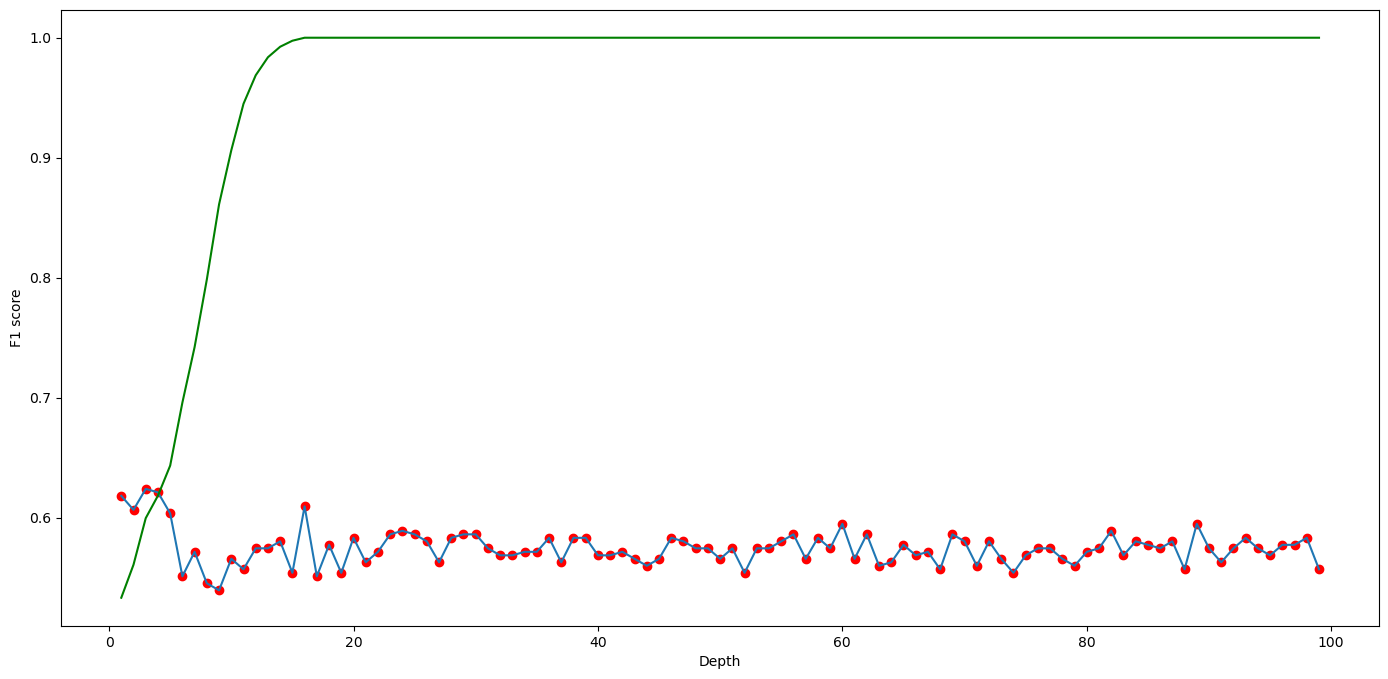

In [111]:
plt.figure(figsize=(17,8))
plt.plot(Iarray, AccScore)
plt.plot(Iarray, AccTrainScore, color="green")
plt.scatter(Iarray, AccScore, color="red")
plt.ylabel("F1 score")
plt.xlabel("Depth")

##### Question 10: How would you detect overfitting in classification? Do this check for all models you tested in question 8 and plot the results. Would you choose a different max_depth now?

In [ ]:
TreeModel_Deg0 = DecisionTreeClassifier()
TreeModel_Deg4 = DecisionTreeClassifier(max_depth=4)
TreeModel_Deg0.fit(X_train, y_train)
TreeModel_Deg4.fit(X_train, y_train)

accuracy1 = TreeModel_Deg0.score(X_test, y_test)
accuracy2 = TreeModel_Deg4.score(X_test, y_test)
print(f"Accuracy comparison: {accuracy1} >< {accuracy2}")

mypred = TreeModel_Deg0.predict(X_test)
newpred = TreeModel_Deg4.predict(X_test)
Precision0 = precision_score(y_test, mypred, average="weighted")
Precision1 = precision_score(y_test, newpred, average="weighted")
print(f"Precision comparison: {Precision} >< {Precision1}")

SS = specificity_score(y_test, mypred, average="weighted")
print("Specificity score:",SS)

RecallScore = recall_score(y_test, mypred, average="weighted")
print("Recall score:",RecallScore)

F1score = f1_score(y_test, mypred, average="weighted")
print("F1 score:",F1score)

##### Question 11: A variant of Decision trees is called 'Random Forest'. In random forest, we create a number of decision trees who each make a prediction and take the average outcome. For classification, this is the outcome that occurs the most over all decision trees. Based on the [documentation](https://scikit-learn.org/dev/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier) (or you can experiment yourself, it is very similar to decision trees so I'm sure you can figure it out!) create a model for a random forest and report on the accuracy/precision.

##### Question 12: Would a randomforest be more or less prone to overfitting than a decision tree? Study up on the exact workings of a random forest and elaborate.